# 16 — Activation functions

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–15, especially the MLP built from scratch (13), backpropagation and the upstream gradient (14), and `nn.Module` with forward hooks (15) |
| **You will learn** | What an activation function must provide; how its derivative enters backpropagation; sigmoid and tanh, their maximum slopes, saturation, and why outputs that are always positive couple a unit's weight gradients; ReLU, its sparsity, and dead units, measured with forward hooks; Leaky ReLU, ELU, GELU and SiLU with autograd-checked derivatives; a multi-seed comparison of six activations on the same task; ReLU networks as piecewise-linear functions |
| **Estimated time** | About 2.5 hours, plus 1–2 hours for the exercises |
| **Compute** | CPU only, about a minute. No GPU section: every network here is small and full-batch. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import math
import copy

import torch.nn.functional as F
from torch import nn

from dlcourse.data import make_checkerboard, make_spirals
from dlcourse.plotting import COLORS, plot_dataset, plot_decision_boundary

f64 = torch.float64

## The motivating problem

Two facts from earlier notebooks pull in opposite directions:

- **Without a nonlinearity, depth is useless.** Notebook 02 showed that stacked affine layers collapse into one affine map, however many there are.
- **With a step nonlinearity, nothing trains.** Notebook 11 showed that the step's derivative is 0 wherever it exists, so gradient descent gets no signal for hidden weights.

So the function $\varphi$ applied between layers must be nonlinear *and* have useful derivatives. Notebook 11 used the sigmoid, notebook 12 the ReLU, and notebook 13 built an MLP with one of them. But which one should a network use? Historically the field moved from sigmoid and tanh (1980s–2000s) to the ReLU (around 2010–2012) and then, in Transformers, to smooth variants such as GELU (from 2018). This notebook asks **why**, and answers with derivations and measurements:

1. What does backpropagation need from $\varphi$?
2. Why do sigmoid networks train slowly, or not at all, as they get deeper?
3. What does the ReLU fix, and what new failure ("dead units") does it introduce?
4. How do the modern alternatives compare on the same task?

Notation follows notebooks 13–14: for layer $\ell$, the pre-activation is $A^{(\ell)} = H^{(\ell-1)} W^{(\ell)\top} + \mathbf b^{(\ell)}$ of shape $(N, n_\ell)$, the activation is $H^{(\ell)} = \varphi(A^{(\ell)})$ applied elementwise, and $H^{(0)} = X$.

## 1. What an activation function must do

Three requirements, in order of importance:

1. **Nonlinear.** Otherwise $\varphi(A) = cA + d$ and the whole network is one affine map (notebook 02).
2. **Differentiable almost everywhere, with a derivative that is not almost always zero.** Backpropagation multiplies by $\varphi'$, so a $\varphi'$ that is zero (the step) or tiny (as we will see, a saturated sigmoid) stops learning. A few points without a derivative, like ReLU's corner at 0, are harmless: frameworks pick a value there (notebook 03).
3. **Cheap.** $\varphi$ is evaluated for every unit, every example, and every step, forward and backward.

A quick reminder of requirement 1, with a linear "activation":

In [3]:
set_seed(0)
lin1, lin2 = nn.Linear(2, 8), nn.Linear(8, 3)
x_demo = torch.randn(5, 2)                                       # (5, 2)
stacked = lin2(lin1(x_demo))                                     # identity "activation"
W_comb = lin2.weight @ lin1.weight                               # (3, 2)
b_comb = lin2.weight @ lin1.bias + lin2.bias                     # (3,)
print("two layers without activation == one affine layer:", torch.allclose(stacked, x_demo @ W_comb.T + b_comb, atol=1e-6))

two layers without activation == one affine layer: True


### Where $\varphi'$ enters backpropagation

Because $\varphi$ acts **elementwise**, $H_{ik} = \varphi(A_{ik})$ depends only on $A_{ik}$. Its Jacobian is diagonal (notebook 03), so the vector–Jacobian product of notebook 14 is an elementwise product. With the upstream gradient $G = \partial L / \partial H$ (same shape as $H$, $(N, n)$):

$$\frac{\partial L}{\partial A} = G \odot \varphi'(A).$$

Every gradient that reaches the weights *below* this layer passes through this product. If $\varphi'(A)$ is small, everything below receives a small gradient; if it is exactly 0, nothing below learns from those entries. That one line is the reason the choice of activation matters for training, and the rest of the notebook is largely about the values $\varphi'$ takes.

Let us confirm the formula for $\tanh$, whose derivative $1 - \tanh^2$ we derived in notebook 03.

In [4]:
set_seed(0)
A = torch.randn(4, 5, dtype=f64, requires_grad=True)          # pre-activations (N=4, n=5)
G = torch.randn(4, 5, dtype=f64)                               # an arbitrary upstream gradient
H = torch.tanh(A)
(grad_A_autograd,) = torch.autograd.grad(H, A, grad_outputs=G)
grad_A_formula = G * (1 - torch.tanh(A) ** 2)
print("max |autograd - G * tanh'(A)|:", (grad_A_autograd - grad_A_formula).abs().max().item())

max |autograd - G * tanh'(A)|: 0.0


### Checkpoint 1.1

Do the same for the sigmoid. Write `sigmoid_vjp(A, G)` that returns $\partial L/\partial A$ when $H = \sigma(A)$ and $G = \partial L/\partial H$, **using the formula** $\sigma' = \sigma(1 - \sigma)$ (notebook 03), not autograd. `A` and `G` have the same (any) shape.

<details>
<summary><b>💡 Hint</b></summary>

`s = torch.sigmoid(A)`, then `G * s * (1 - s)`. Use `A.detach()` if you want to avoid building a graph; it does not matter for the check.

</details>

In [ ]:
def sigmoid_vjp(A, G):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
_got = sigmoid_vjp(A, G)
check_shape(_got, (4, 5), "sigmoid_vjp(A, G)")
(_ref,) = torch.autograd.grad(torch.sigmoid(A), A, grad_outputs=G)
check_close(_got, _ref, "sigmoid_vjp on the random A", rtol=1e-10, atol=1e-12)
# deterministic edge cases: z = 0 (slope exactly 1/4), moderate and extreme pre-activations (slope -> 0)
_A_edge = torch.tensor([0.0, 2.0, -2.0, 40.0, -40.0, 1000.0, -1000.0], dtype=f64)
_G_edge = torch.tensor([1.0, -3.0, 2.0, 1.0, 1.0, 5.0, -5.0], dtype=f64)
_got_edge = sigmoid_vjp(_A_edge, _G_edge)
check_close(_got_edge[0], torch.tensor(0.25, dtype=f64), "sigmoid_vjp at z = 0 with G = 1", rtol=0, atol=1e-15)
check_close(_got_edge, _G_edge * torch.sigmoid(_A_edge) * torch.sigmoid(-_A_edge), "sigmoid_vjp on edge cases", rtol=1e-9, atol=1e-15)
check(torch.isfinite(_got_edge).all(), "sigmoid_vjp should be finite (0, not NaN) for |z| = 1000")
check_shape(sigmoid_vjp(torch.zeros(2, 3, 4), torch.ones(2, 3, 4)), (2, 3, 4), "output for a (2, 3, 4) input")
passed("Checkpoint 1.1")

## 2. Sigmoid and tanh

The two classical activations are

$$\sigma(z) = \frac{1}{1 + e^{-z}} \in (0, 1), \qquad \tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}} \in (-1, 1),$$

with derivatives (notebook 03)

$$\sigma'(z) = \sigma(z)\,\big(1 - \sigma(z)\big), \qquad \tanh'(z) = 1 - \tanh^2(z).$$

**Maximum slopes.** $\sigma(1 - \sigma)$ is a product $p(1-p)$ with $p \in (0, 1)$, largest at $p = \tfrac12$, i.e. at $z = 0$: $\sigma'(z) \le \tfrac14$. And $1 - \tanh^2 \le 1$, with equality only at $z = 0$.

**They are the same curve, rescaled.** Multiply the numerator and denominator of $\tanh$ by $e^{-z}$:

$$\tanh(z) = \frac{1 - e^{-2z}}{1 + e^{-2z}} = \frac{2}{1 + e^{-2z}} - 1 = 2\sigma(2z) - 1.$$

So a tanh unit is a sigmoid unit with its input doubled and its output stretched from $(0, 1)$ to $(-1, 1)$. Any network of one kind can be rewritten as a network of the other by rescaling weights and biases, so they have the same representational power. They differ in **how they train**, through two properties: the size of the derivative and whether the output is centered at 0.

In [7]:
z = torch.linspace(-8, 8, 160_001, dtype=f64)                   # (160001,), contains z = 0
sig, th = torch.sigmoid(z), torch.tanh(z)
dsig, dth = sig * (1 - sig), 1 - th**2
print(f"max |tanh(z) - (2σ(2z) - 1)|  = {(th - (2 * torch.sigmoid(2 * z) - 1)).abs().max().item():.2e}")
print(f"max σ'(z) = {dsig.max().item():.6f} at z = {z[dsig.argmax()].item():+.4f}")
print(f"max tanh'(z) = {dth.max().item():.6f} at z = {z[dth.argmax()].item():+.4f}")
print("\n   z      σ'(z)       tanh'(z)")
for zz in [0.0, 1.0, 2.0, 3.0, 5.0, 10.0]:
    t = torch.tensor(zz, dtype=f64)
    print(f"{zz:5.1f}   {(torch.sigmoid(t) * (1 - torch.sigmoid(t))).item():.3e}   {(1 - torch.tanh(t) ** 2).item():.3e}")

max |tanh(z) - (2σ(2z) - 1)|  = 3.33e-16
max σ'(z) = 0.250000 at z = -0.0000
max tanh'(z) = 1.000000 at z = -0.0000

   z      σ'(z)       tanh'(z)
  0.0   2.500e-01   1.000e+00
  1.0   1.966e-01   4.200e-01
  2.0   1.050e-01   7.065e-02
  3.0   4.518e-02   9.866e-03
  5.0   6.648e-03   1.816e-04
 10.0   4.540e-05   8.245e-09


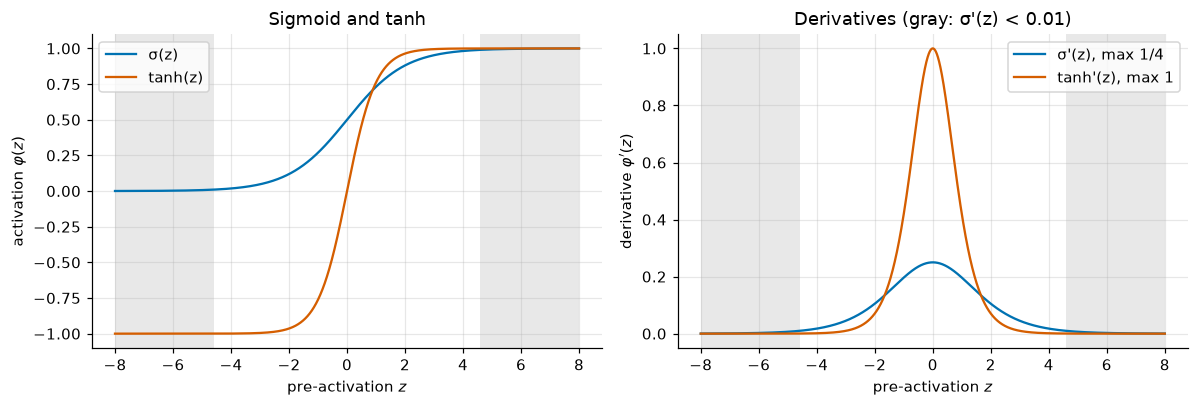

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(z, sig, color=COLORS[0], label="σ(z)")
axes[0].plot(z, th, color=COLORS[1], label="tanh(z)")
axes[0].set_xlabel("pre-activation $z$")
axes[0].set_ylabel("activation $\\varphi(z)$")
axes[0].set_title("Sigmoid and tanh")
axes[0].legend()
axes[1].plot(z, dsig, color=COLORS[0], label="σ'(z), max 1/4")
axes[1].plot(z, dth, color=COLORS[1], label="tanh'(z), max 1")
for ax in axes:
    ax.axvspan(-8, -4.585, color="0.85", alpha=0.6, lw=0)
    ax.axvspan(4.585, 8, color="0.85", alpha=0.6, lw=0)
axes[1].set_xlabel("pre-activation $z$")
axes[1].set_ylabel("derivative $\\varphi'(z)$")
axes[1].set_title("Derivatives (gray: σ'(z) < 0.01)")
axes[1].legend()
plt.tight_layout()
plt.show()

Two things to notice. The sigmoid's derivative never exceeds $1/4$, a quarter of tanh's peak. And both derivatives decay **exponentially** away from 0 (for large $z$, $\sigma'(z) \approx e^{-z}$ and $\tanh'(z) \approx 4e^{-2z}$): in the gray regions the unit is **saturated**, its output is pinned near its limit, and almost no gradient passes through it. A unit with $|z| = 10$ passes a fraction $4.5 \times 10^{-5}$ (sigmoid) or $8 \times 10^{-9}$ (tanh) of its upstream gradient.

### Checkpoint 2.1

The gray band in the plot starts where $\sigma'(z) = 0.01$. Find the positive solution `z_sat` of $\sigma(z)(1 - \sigma(z)) = 0.01$ **in closed form**: first solve the quadratic $p(1 - p) = 0.01$ for $p = \sigma(z) > \tfrac12$, then invert the sigmoid with $z = \ln\frac{p}{1-p}$ (notebook 09). Store it as a Python float.

<details>
<summary><b>💡 Hint</b></summary>

$p^2 - p + 0.01 = 0$ gives $p = \frac{1 + \sqrt{1 - 0.04}}{2}$. Then `math.log(p / (1 - p))`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"z_sat = {z_sat:.4f}")

In [ ]:
check(isinstance(z_sat, float), "z_sat should be a Python float")
_t = torch.tensor(z_sat, dtype=f64)
check_close((torch.sigmoid(_t) * (1 - torch.sigmoid(_t))).item(), 0.01, "σ'(z_sat)", rtol=1e-9, atol=0)
check(z_sat > 0, "take the positive solution")
passed("Checkpoint 2.1")

### Gradients through a chain of sigmoids

Saturation hurts one unit. Depth multiplies the effect. Take the simplest deep network: a **chain** of $L$ scalar units, $h_\ell = \varphi(w_\ell h_{\ell-1} + b_\ell)$. By the chain rule,

$$\frac{\partial h_L}{\partial h_0} = \prod_{\ell=1}^{L} w_\ell\,\varphi'(a_\ell), \qquad a_\ell = w_\ell h_{\ell - 1} + b_\ell.$$

For the sigmoid each factor $\varphi'(a_\ell)$ is at most $\tfrac14$, so with $|w_\ell| \le 1$ the gradient reaching the first unit is at most $4^{-L}$: ten layers, less than $10^{-6}$. This is the **vanishing gradient problem**, identified for recurrent networks by Hochreiter (1991) and Bengio, Simard and Frasconi (1994). Larger weights can offset the $\tfrac14$ only by also pushing $a_\ell$ further from 0, into saturation; how to choose the weight scale is notebook 18's subject.

In a real layer the same thing happens with matrices: the backward pass alternates "$\odot\,\varphi'(A^{(\ell)})$" and "multiply by $W^{(\ell)}$" (notebook 14), and every $\odot\,\sigma'$ scales its entries by at most $\tfrac14$.

Let us measure the chain with $w_\ell = 1$, $b_\ell = 0$ and $h_0 = 0.5$, using autograd.

In [11]:
def chain_gradients(phi, L_max, h0=0.5):
    """d h_L / d h_0 for L = 1..L_max in the chain h_l = phi(h_{l-1}) (w = 1, b = 0). Returns (L_max,) float64."""
    h0 = torch.tensor(h0, dtype=f64, requires_grad=True)
    h, grads = h0, []
    for _ in range(L_max):
        h = phi(h)
        (g,) = torch.autograd.grad(h, h0, retain_graph=True)
        grads.append(g.item())
    return torch.tensor(grads, dtype=f64)


L_max = 30
Ls = torch.arange(1, L_max + 1)
g_sig = chain_gradients(torch.sigmoid, L_max)
g_tanh = chain_gradients(torch.tanh, L_max)
for L in [1, 5, 10, 20, 30]:
    print(f"L = {L:2d}: sigmoid {g_sig[L - 1]:.3e}   bound 4^-L = {4.0 ** -L:.3e}   tanh {g_tanh[L - 1]:.3e}")
print(f"sigmoid: ratio of consecutive gradients at L = 30: {(g_sig[-1] / g_sig[-2]).item():.4f}")

L =  1: sigmoid 2.350e-01   bound 4^-L = 2.500e-01   tanh 7.864e-01
L =  5: sigmoid 6.080e-04   bound 4^-L = 9.766e-04   tanh 3.930e-01
L = 10: sigmoid 3.483e-07   bound 4^-L = 9.537e-07   tanh 2.228e-01
L = 20: sigmoid 1.143e-13   bound 4^-L = 9.095e-13   tanh 1.073e-01
L = 30: sigmoid 3.751e-20   bound 4^-L = 8.674e-19   tanh 6.584e-02
sigmoid: ratio of consecutive gradients at L = 30: 0.2247


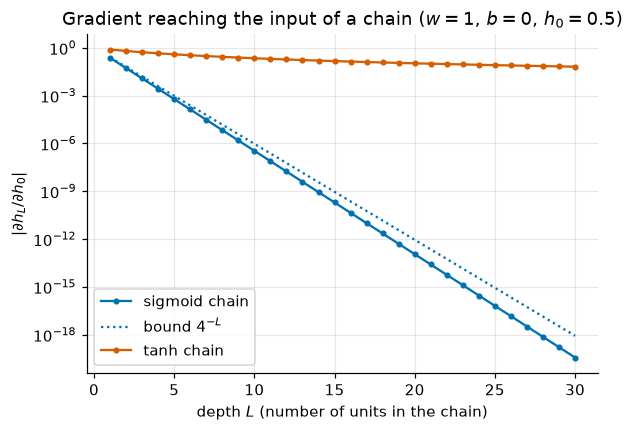

In [12]:
plt.semilogy(Ls, g_sig, "o-", ms=3, color=COLORS[0], label="sigmoid chain")
plt.semilogy(Ls, 4.0 ** -Ls.double(), ":", color=COLORS[0], label="bound $4^{-L}$")
plt.semilogy(Ls, g_tanh, "o-", ms=3, color=COLORS[1], label="tanh chain")
plt.xlabel("depth $L$ (number of units in the chain)")
plt.ylabel("$|\\partial h_L / \\partial h_0|$")
plt.title("Gradient reaching the input of a chain ($w = 1$, $b = 0$, $h_0 = 0.5$)")
plt.legend()
plt.show()

The sigmoid chain's gradient falls by a constant factor of about $0.22$ per unit, slightly faster than the bound: after 30 units it is about $10^{-20}$. The tanh chain loses far less ($0.066$ after 30 units), and its per-unit factor approaches 1, because here $h_\ell = \tanh(h_{\ell-1})$ drifts towards 0, where $\tanh' \approx 1$. That is the advantage of tanh's peak slope of 1 — but it depends on pre-activations staying near 0. Give the tanh chain large weights or biases and its units saturate just like sigmoids; keeping pre-activations in the useful range is what initialization (notebook 18) is about. Section 5 measures the same effect in real layers.

### Checkpoint 2.2

Why a constant factor? The sigmoid chain with $w = 1, b = 0$ converges to a **fixed point** $h^\ast = \sigma(h^\ast)$, and once there every unit contributes the same factor $\sigma'(h^\ast)$. Find `h_star` by iterating $h \leftarrow \sigma(h)$ from $h = 0.5$ (200 iterations is plenty), then compute `factor = σ'(h_star)`. Both should be Python floats. Compare `factor` with the ratio printed above.

<details>
<summary><b>💡 Hint</b></summary>

Use a `float64` tensor and a `for` loop: `h = torch.sigmoid(h)`. Then `s = torch.sigmoid(h)` and `factor = (s * (1 - s)).item()`. Note $\sigma'(h^\ast)$ is evaluated at the pre-activation $a = h^\ast$ (since $w = 1$, $b = 0$).

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"h* = {h_star:.6f}, σ'(h*) = {factor:.6f}")

In [ ]:
check(isinstance(h_star, float) and isinstance(factor, float), "h_star and factor should be Python floats")
check_close(h_star, torch.sigmoid(torch.tensor(h_star, dtype=f64)).item(), "h_star should satisfy h = σ(h)", rtol=0, atol=1e-10)
check_close(factor, (g_sig[-1] / g_sig[-2]).item(), "factor vs the measured ratio", rtol=0, atol=1e-6)
passed("Checkpoint 2.2")

### Zero-centered outputs

The second difference between sigmoid and tanh is subtler. Consider unit $j$ of layer $\ell + 1$, with pre-activation $a_j = \sum_k W_{jk} h_k + b_j$, where $h_k$ are the activations of layer $\ell$. For **one example**, with $\delta_j = \partial L / \partial a_j$ (a scalar),

$$\frac{\partial L}{\partial W_{jk}} = \delta_j\, h_k.$$

If layer $\ell$ is a **sigmoid** layer, every $h_k > 0$, so every entry of the gradient row $\partial L / \partial W_{j,:}$ has the **same sign** as $\delta_j$. A gradient step on this example can only increase all of unit $j$'s incoming weights together, or decrease them all together. Reaching a weight vector that needs some weights up and others down then requires a zig-zag of steps. LeCun, Bottou, Orr and Müller (1998, "Efficient BackProp") pointed this out as a reason to prefer inputs and activations with mean near 0, and hence tanh over the sigmoid. With tanh, the $h_k$ have both signs and the constraint disappears.

Over a **batch**, the gradient is a sum of such rows with different $\delta_j$, so the constraint is softened, but the rows are still strongly aligned. Let us verify both statements on a small random network applied to the spirals.

In [15]:
X_sp, y_sp = make_spirals(n=300, classes=3, seed=0)     # (900, 2), (900,)


def row_sign_agreement(act, n_examples=200, seed=0):
    """For net = Linear(2,16) -> act -> Linear(16,3), the fraction of rows of the second layer's weight gradient
    whose 16 entries all share one sign: per example (averaged), and for the full-batch gradient."""
    set_seed(seed)
    net = nn.Sequential(nn.Linear(2, 16), act, nn.Linear(16, 3))
    W2 = net[2].weight                                                       # (3, 16)
    per_example = []
    for i in range(n_examples):
        (g,) = torch.autograd.grad(F.cross_entropy(net(X_sp[i : i + 1]), y_sp[i : i + 1]), W2)   # (3, 16)
        per_example.append(((g > 0).all(1) | (g < 0).all(1)).float().mean().item())
    (g_batch,) = torch.autograd.grad(F.cross_entropy(net(X_sp), y_sp), W2)
    batch = ((g_batch > 0).all(1) | (g_batch < 0).all(1)).float().mean().item()
    return sum(per_example) / n_examples, batch


for name, act in [("sigmoid", nn.Sigmoid()), ("tanh", nn.Tanh())]:
    for seed in range(3):
        pe, b = row_sign_agreement(act, seed=seed)
        print(f"{name:8s} seed {seed}: rows with one sign — per example {pe:.2f}, full-batch gradient {b:.2f}")

sigmoid  seed 0: rows with one sign — per example 1.00, full-batch gradient 1.00
sigmoid  seed 1: rows with one sign — per example 1.00, full-batch gradient 0.67
sigmoid  seed 2: rows with one sign — per example 1.00, full-batch gradient 1.00
tanh     seed 0: rows with one sign — per example 0.00, full-batch gradient 0.00
tanh     seed 1: rows with one sign — per example 0.00, full-batch gradient 0.00
tanh     seed 2: rows with one sign — per example 0.00, full-batch gradient 0.00


With sigmoid hidden units, **every** per-example gradient row has a single sign (fraction 1.00), exactly as derived; with tanh, none do. For the full-batch gradient, all three rows of the sigmoid network still had a single sign for seeds 0 and 2, and two of three for seed 1, while tanh's never did. The effect is an inefficiency, not a wall: networks with sigmoid hidden layers do train. The far bigger problem is the vanishing gradient above, and the next activation fixes that.

## 3. ReLU: no saturation, but dead units

The **rectified linear unit**

$$\operatorname{relu}(z) = \max(z, 0), \qquad \operatorname{relu}'(z) = \begin{cases} 1 & z > 0 \\ 0 & z < 0 \end{cases}$$

(PyTorch uses $\operatorname{relu}'(0) = 0$) was popularized for deep networks by Nair and Hinton (2010) and Glorot, Bordes and Bengio (2011), and AlexNet (Krizhevsky, Sutskever and Hinton, 2012) reported training several times faster with ReLUs than with tanh units. Compared with the sigmoid:

- **No saturation for $z > 0$.** An active unit passes its upstream gradient through unchanged ($G \odot 1$). In the scalar chain, the product of $\varphi'$ factors is exactly 1 as long as every unit is active; only the weights scale the gradient.
- **Cheap.** A comparison, no exponential.
- **Sparse.** For a given input, the units with $z < 0$ output exactly 0. At a typical initialization about half of them are off.

The price is the other branch: for $z < 0$ the derivative is exactly 0. Let us first measure the sparsity of a freshly initialized network on the spirals.

In [16]:
def relu_mlp(width=64, depth=3, act=nn.ReLU, first_bias=0.0, seed=0, n_out=3):
    """depth hidden layers of `width` units with activation `act` (a class or zero-argument factory).
    Kaiming-normal weights (notebook 18), zero biases except the first layer's, which are set to `first_bias`."""
    set_seed(seed)
    layers, d = [], 2
    for _ in range(depth):
        lin = nn.Linear(d, width)
        nn.init.kaiming_normal_(lin.weight, nonlinearity="relu")
        nn.init.zeros_(lin.bias)
        layers += [lin, act()]
        d = width
    layers.append(nn.Linear(d, n_out))
    net = nn.Sequential(*layers)
    with torch.no_grad():
        net[0].bias.fill_(first_bias)
    return net


net0 = relu_mlp()
with torch.no_grad():
    h = X_sp
    for i, m in enumerate(net0):
        h = m(h)
        if isinstance(m, nn.ReLU):
            print(f"hidden layer {i // 2 + 1}: fraction of exact zeros in H = {(h == 0).float().mean().item():.3f}")

hidden layer 1: fraction of exact zeros in H = 0.503
hidden layer 2: fraction of exact zeros in H = 0.515
hidden layer 3: fraction of exact zeros in H = 0.482


Close to half in every layer, as expected for pre-activations that are roughly symmetric around 0. Sparsity in itself is fine: a different subset of units is active for different inputs, which is exactly how a ReLU network bends space into pieces (notebook 12).

### Dead units

The problem comes when a unit is off for **every** training input. Suppose $A^{(\ell)}_{ij} \le 0$ for all examples $i$. Then $\varphi'(A^{(\ell)}_{ij}) = 0$ for all $i$, so column $j$ of $\partial L / \partial A^{(\ell)} = G \odot \varphi'(A^{(\ell)})$ is zero, and the unit's parameter gradients vanish:

$$\frac{\partial L}{\partial W^{(\ell)}_{j,:}} = \sum_i \frac{\partial L}{\partial A^{(\ell)}_{ij}}\, H^{(\ell-1)}_{i,:} = \mathbf 0, \qquad \frac{\partial L}{\partial b^{(\ell)}_j} = \sum_i \frac{\partial L}{\partial A^{(\ell)}_{ij}} = 0.$$

Gradient descent never changes this unit's weights or bias. We call such a unit **dead**. Whether it stays dead depends on where it sits:

- In the **first** hidden layer its inputs are the data, which do not change. Its pre-activations never change, so under full-batch gradient descent on the same data it is **dead forever**.
- In a **deeper** layer its inputs $H^{(\ell-1)}$ change as the layers below train, so its pre-activations can become positive again for some inputs: it can **revive**.

(With mini-batches, "dead" should be measured on the whole training set, not one batch; with weight decay, notebook 23, a dead unit's weights additionally shrink towards 0.)

To measure deadness during training, we need every hidden layer's pre-activations at every step without changing the model. That is what **forward hooks** (notebook 15) are for: a hook registered on each activation module receives `(module, inputs, output)` on every forward call. The input of the activation module *is* the pre-activation $A^{(\ell)}$.

In [17]:
class DeadUnitMonitor:
    """Forward hooks on every activation module of an nn.Sequential MLP (every module that is not nn.Linear).
    After a forward pass on the full training set, `alive[l]` is a (n_l,) bool tensor: True where the
    unit's pre-activation was positive for at least one input."""

    def __init__(self, net):
        self.modules = [m for m in net if not isinstance(m, nn.Linear)]
        self.alive = [None] * len(self.modules)
        self.handles = [m.register_forward_hook(self._make_hook(l)) for l, m in enumerate(self.modules)]

    def _make_hook(self, l):
        def hook(module, inputs, output):
            A = inputs[0].detach()                # pre-activation (N, n_l)
            self.alive[l] = (A > 0).any(dim=0)    # (n_l,)
        return hook

    def dead_fractions(self):
        return [1 - a.float().mean().item() for a in self.alive]

    def remove(self):
        for h in self.handles:
            h.remove()


def train_monitored(net, X, y, lr, steps, every=25):
    """Full-batch SGD on cross-entropy. Records (step, loss, accuracy, dead fraction per hidden layer)."""
    monitor = DeadUnitMonitor(net)
    opt = torch.optim.SGD(net.parameters(), lr=lr)
    history = []
    for t in range(steps + 1):
        opt.zero_grad()
        logits = net(X)                            # hooks fire here, on the whole training set
        loss = F.cross_entropy(logits, y)
        if t % every == 0:
            acc = (logits.argmax(1) == y).float().mean().item()
            history.append((t, loss.item(), acc, monitor.dead_fractions()))
        if t < steps:
            loss.backward()
            opt.step()
    monitor.remove()
    return history

Now two runs on the spirals: the network above, and the same network with every first-layer bias initialized to $-1.5$ instead of 0. Since the inputs lie roughly in $[-1, 1]^2$, a bias of $-1.5$ pushes many first-layer units below 0 everywhere. (A badly chosen initialization is one way to produce dead units; a large learning rate is another, which Exercise 4 investigates.)

In [18]:
runs_dead = {}
for label, b0 in [("first-layer bias 0", 0.0), ("first-layer bias −1.5", -1.5)]:
    net = relu_mlp(first_bias=b0)
    runs_dead[label] = (net, train_monitored(net, X_sp, y_sp, lr=0.5, steps=1500))
    t, loss, acc, dead = runs_dead[label][1][-1]
    print(f"{label:22s}: dead at step 0 {[round(d, 3) for d in runs_dead[label][1][0][3]]}, "
          f"at step {t} {[round(d, 3) for d in dead]};  final loss {loss:.3f}, accuracy {acc:.3f}")

first-layer bias 0    : dead at step 0 [0.0, 0.062, 0.219], at step 1500 [0.0, 0.0, 0.0];  final loss 0.095, accuracy 0.966


first-layer bias −1.5 : dead at step 0 [0.828, 0.0, 0.016], at step 1500 [0.828, 0.016, 0.016];  final loss 0.613, accuracy 0.748


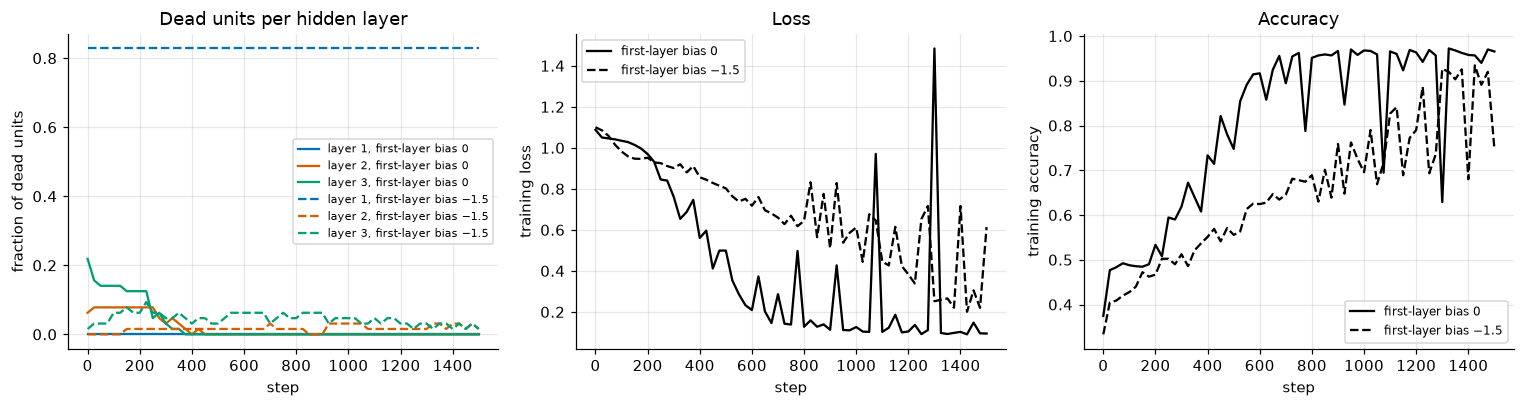

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for (label, (net, hist)), ls in zip(runs_dead.items(), ["-", "--"]):
    steps_ = [h[0] for h in hist]
    for l in range(3):
        axes[0].plot(steps_, [h[3][l] for h in hist], ls, color=COLORS[l], label=f"layer {l + 1}, {label}")
    axes[1].plot(steps_, [h[1] for h in hist], ls, color=COLORS[7], label=label)
    axes[2].plot(steps_, [h[2] for h in hist], ls, color=COLORS[7], label=label)
axes[0].set_ylabel("fraction of dead units")
axes[0].set_title("Dead units per hidden layer")
axes[0].legend(fontsize=7)
axes[1].set_ylabel("training loss")
axes[1].set_title("Loss")
axes[1].legend(fontsize=8)
axes[2].set_ylabel("training accuracy")
axes[2].set_title("Accuracy")
axes[2].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("step")
plt.tight_layout()
plt.show()

With bias $-1.5$, 83% of the first layer (53 of 64 units) starts dead, and that number **never changes** in 1500 steps (flat blue dashed line): the network effectively has an 11-unit first layer, and its loss stays well above the baseline's throughout. (Both runs show occasional loss spikes: a learning rate of 0.5 is near the edge of stability for this network, a topic for notebook 19. The final accuracies, 0.966 and 0.748, are snapshots of noisy curves; the gap between the curves is the robust observation.) In the baseline, some units of the deeper layers are dead at step 0 (about a fifth of layer 3), and they **revive** within a few hundred steps as the layers below change — exactly the distinction derived above.

Let us confirm that the dead first-layer units receive exactly zero gradient, and that their parameters are exactly where they started.

In [20]:
net_b = runs_dead["first-layer bias −1.5"][0]
fresh = relu_mlp(first_bias=-1.5)                         # same seed: the initial parameters of net_b
with torch.no_grad():
    dead1 = ~((X_sp @ net_b[0].weight.T + net_b[0].bias) > 0).any(0)     # (64,) dead first-layer units
net_b.zero_grad()
F.cross_entropy(net_b(X_sp), y_sp).backward()
print("dead first-layer units:", dead1.sum().item())
print("max |gradient| of their weights and biases:",
      max(net_b[0].weight.grad[dead1].abs().max().item(), net_b[0].bias.grad[dead1].abs().max().item()))
print("max change of their weights since initialization:", (net_b[0].weight[dead1] - fresh[0].weight[dead1]).abs().max().item())
print("max change of the live units' weights:          ", (net_b[0].weight[~dead1] - fresh[0].weight[~dead1]).abs().max().item())

dead first-layer units: 53
max |gradient| of their weights and biases: 0.0
max change of their weights since initialization: 0.0
max change of the live units' weights:           2.5911436080932617


Exactly 0 and exactly 0: not small, zero. The live units, by contrast, moved substantially. No amount of further training on this data will bring those 53 units back.

**What "dead" assumes.** The monitor calls a unit dead relative to the inputs it was shown, the training set. That is the right notion for training (it decides which gradients are zero), but it is not a property of the function: the same unit can be active on other inputs. A counterexample, using inputs on a wider square $[-3, 3]^2$ that the network never saw:

In [21]:
g = torch.linspace(-3, 3, 301)
wide = torch.stack(torch.meshgrid(g, g, indexing="xy"), dim=-1).reshape(-1, 2)          # (90601, 2)
with torch.no_grad():
    alive_wide = ((wide @ net_b[0].weight.T + net_b[0].bias) > 0).any(0)               # (64,)
print(f"of the {dead1.sum().item()} units dead on the training set, {(alive_wide & dead1).sum().item()} "
      f"are active somewhere on [-3, 3]²")

of the 53 units dead on the training set, 51 are active somewhere on [-3, 3]²


51 of the 53 "dead" units turn on somewhere in the wider square: their half-planes $\mathbf w_j \cdot \mathbf x + b_j > 0$ simply miss the region where the training data lie. So "dead" means "dead on this data": it says nothing about inputs from elsewhere, and a unit dead on one training set could be alive on another. A monitor that only saw a mini-batch would make the same kind of error in the other direction, calling units dead that are active on examples outside the batch.

### Checkpoint 3.1

Register your own forward hook. On the **trained baseline** network `runs_dead["first-layer bias 0"][0]`, attach a hook to the ReLU module of hidden layer 2 (index 3 in the `nn.Sequential`) that stores the module's **output** in a list, run the network on `X_sp`, remove the hook, and compute `sparsity2`: the fraction of exact zeros in that output (a Python float). Is it still close to one half after training?

<details>
<summary><b>💡 Hint</b></summary>

`stored = []`, then `handle = net[3].register_forward_hook(lambda module, inputs, output: stored.append(output.detach()))`. Run `net(X_sp)` inside `torch.no_grad()`, then `handle.remove()`, and `(stored[0] == 0).float().mean().item()`.

</details>

In [ ]:
net_base = runs_dead["first-layer bias 0"][0]
# YOUR CODE HERE
raise NotImplementedError
print(f"fraction of zeros in hidden layer 2 after training: {sparsity2:.3f}")

In [ ]:
check(isinstance(sparsity2, float), "sparsity2 should be a Python float")
check(len(net_base[3]._forward_hooks) == 0, "remove the hook when you are done (handle.remove())")
with torch.no_grad():
    _h2 = net_base[:4](X_sp)
check_close(sparsity2, (_h2 == 0).float().mean().item(), "sparsity2", rtol=0, atol=1e-9)
passed("Checkpoint 3.1")

## 4. Beyond ReLU: Leaky ReLU, ELU, GELU, SiLU

Several activations keep ReLU's behavior for large positive $z$ (slope 1, no saturation) but change the negative side:

- **Leaky ReLU** (Maas, Hannun and Ng, 2013): $\max(\alpha z, z)$ with a small $\alpha$, typically $0.01$. Derivative $1$ for $z > 0$ and $\alpha$ for $z < 0$ (PyTorch uses $\alpha$ at $z = 0$). The gradient is never exactly zero, so a unit that is negative everywhere still learns, slowly. **PReLU** (He et al., 2015) makes $\alpha$ a learned parameter.
- **ELU** (Clevert, Unterthiner and Hochreiter, 2015): $z$ for $z > 0$, $\alpha(e^z - 1)$ for $z \le 0$ (usually $\alpha = 1$). Negative outputs push mean activations towards 0 (the zero-centering argument of Section 2), and the function saturates smoothly at $-\alpha$. Derivative $1$, respectively $\alpha e^z$.
- **GELU** (Hendrycks and Gimpel, 2016): $\operatorname{gelu}(z) = z\,\Phi(z)$, where $\Phi(z) = \tfrac12\big(1 + \operatorname{erf}(z/\sqrt2)\big)$ is the standard normal CDF. ReLU multiplies $z$ by the hard gate $\mathbb 1[z > 0]$; GELU multiplies it by a soft gate, the probability that a standard normal variable is below $z$. Its derivative is $\Phi(z) + z\,\varphi_{\mathcal N}(z)$, with $\varphi_{\mathcal N}(z) = e^{-z^2/2}/\sqrt{2\pi}$ the normal density. The paper also gives a cheaper approximation, $\tfrac12 z\big(1 + \tanh\big(\sqrt{2/\pi}\,(z + 0.044715\,z^3)\big)\big)$. GELU is the default in BERT, GPT-2 and most Transformers since (Chapter 9).
- **SiLU**, also called **Swish** (Elfwing, Uchibe and Doya, 2017; Ramachandran, Zoph and Le, 2017): $z\,\sigma(z)$, the same idea with the logistic sigmoid as the gate. Derivative $\sigma(z)\big(1 + z(1 - \sigma(z))\big)$. It appears in many convolutional networks and, inside the gated "SwiGLU" layer (Shazeer, 2020), in many large language models.

GELU and SiLU are smooth everywhere and **not monotonic**: they dip slightly below 0 for moderately negative $z$ before returning to 0.

We compute every derivative with autograd and compare it with the formula.

In [24]:
z = torch.linspace(-5, 5, 20_001, dtype=f64)                  # (20001,), avoid z = 0 only for the kinks below
Phi = 0.5 * (1 + torch.erf(z / math.sqrt(2)))
pdf = torch.exp(-(z**2) / 2) / math.sqrt(2 * math.pi)
sg = torch.sigmoid(z)
activations = {   # name: (function, derivative formula)
    "sigmoid": (torch.sigmoid, sg * (1 - sg)),
    "tanh": (torch.tanh, 1 - torch.tanh(z) ** 2),
    "ReLU": (F.relu, (z > 0).double()),
    "Leaky ReLU (α=0.1)": (lambda t: F.leaky_relu(t, 0.1), torch.where(z > 0, torch.ones_like(z), torch.full_like(z, 0.1))),
    "ELU (α=1)": (F.elu, torch.where(z > 0, torch.ones_like(z), torch.exp(z))),
    "GELU": (F.gelu, Phi + z * pdf),
    "SiLU": (F.silu, sg * (1 + z * (1 - sg))),
}
values, derivs = {}, {}
for name, (fn, d_formula) in activations.items():
    zz = z.clone().requires_grad_(True)
    out = fn(zz)
    (d_auto,) = torch.autograd.grad(out.sum(), zz)          # elementwise, so the sum's gradient is φ'(z)
    values[name], derivs[name] = out.detach(), d_auto
    print(f"{name:20s} max |autograd − formula| = {(d_auto - d_formula).abs().max().item():.2e}")

sigmoid              max |autograd − formula| = 0.00e+00
tanh                 max |autograd − formula| = 7.64e-18
ReLU                 max |autograd − formula| = 0.00e+00
Leaky ReLU (α=0.1)   max |autograd − formula| = 0.00e+00
ELU (α=1)            max |autograd − formula| = 0.00e+00
GELU                 max |autograd − formula| = 2.22e-16
SiLU                 max |autograd − formula| = 0.00e+00


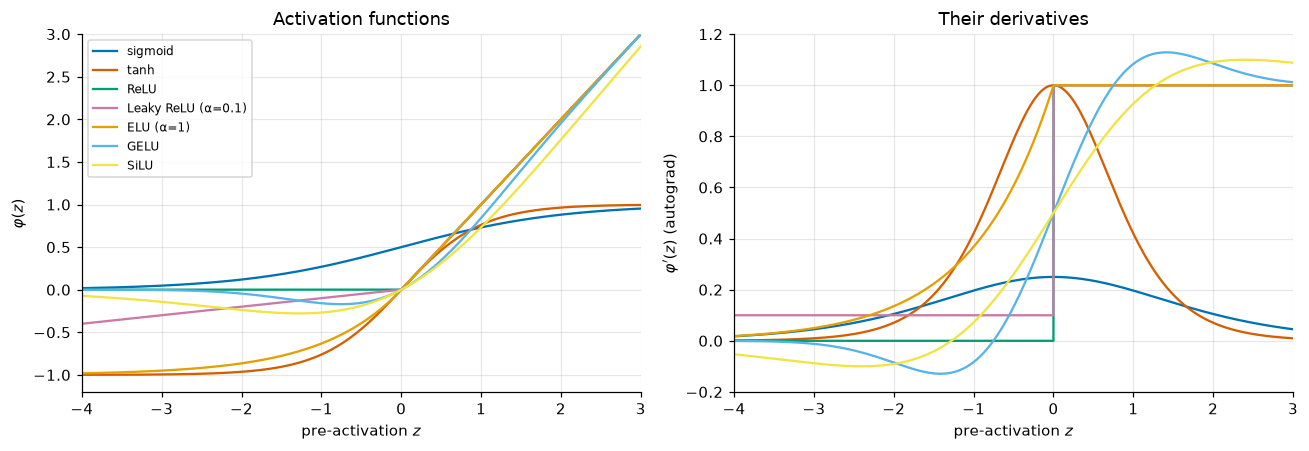

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for (name, v), col in zip(values.items(), COLORS):
    axes[0].plot(z, v, color=col, label=name)
    axes[1].plot(z, derivs[name], color=col, label=name)
axes[0].set_xlim(-4, 3)
axes[0].set_ylim(-1.2, 3)
axes[0].set_xlabel("pre-activation $z$")
axes[0].set_ylabel("$\\varphi(z)$")
axes[0].set_title("Activation functions")
axes[0].legend(fontsize=8)
axes[1].set_xlim(-4, 3)
axes[1].set_ylim(-0.2, 1.2)
axes[1].set_xlabel("pre-activation $z$")
axes[1].set_ylabel("$\\varphi'(z)$ (autograd)")
axes[1].set_title("Their derivatives")
plt.tight_layout()
plt.show()

Every formula matches autograd to rounding error. In the derivative panel, notice the families: sigmoid and tanh are bumps that vanish on both sides; ReLU, Leaky ReLU and ELU are (nearly) steps from a small value to 1; GELU and SiLU are smooth steps that **overshoot** 1 for moderate positive $z$ (about 1.13 and 1.10) and dip **below 0** for moderately negative $z$, where the functions decrease. All the ReLU-like functions have derivative 1 for large positive $z$: none saturate on that side.

How good is GELU's tanh approximation?

In [26]:
gelu_exact = F.gelu(z)
gelu_approx = F.gelu(z, approximate="tanh")
print(f"max |exact − tanh approximation| on [-5, 5]: {(gelu_exact - gelu_approx).abs().max().item():.2e} "
      f"at z = {z[(gelu_exact - gelu_approx).abs().argmax()].item():+.3f}")
print(f"GELU minimum: {gelu_exact.min().item():.4f} at z = {z[gelu_exact.argmin()].item():+.4f}")

max |exact − tanh approximation| on [-5, 5]: 4.73e-04 at z = -2.699
GELU minimum: -0.1700 at z = -0.7520


The approximation is off by less than $5 \times 10^{-4}$ anywhere, far below anything that matters for training; it existed because `erf` used to be slow on some hardware. Some pretrained models (GPT-2, for example) were trained with the approximation, and reproducing them exactly requires using the same variant.

### Checkpoint 4.1

Write `gelu_tanh(x)`, the tanh approximation above, from the formula (only `torch.tanh`, arithmetic, and `math.sqrt`; not `F.gelu`). It must work elementwise on any tensor and support autograd.

<details>
<summary><b>💡 Hint</b></summary>

`0.5 * x * (1 + torch.tanh(math.sqrt(2 / math.pi) * (x + 0.044715 * x**3)))`

</details>

In [ ]:
def gelu_tanh(x):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
_x = torch.linspace(-6, 6, 1001, dtype=f64, requires_grad=True)
_mine = gelu_tanh(_x)
_ref = F.gelu(_x, approximate="tanh")
check_close(_mine, _ref, "gelu_tanh values", rtol=0, atol=1e-12)
(_g_mine,) = torch.autograd.grad(_mine.sum(), _x)
(_g_ref,) = torch.autograd.grad(_ref.sum(), _x)
check_close(_g_mine, _g_ref, "gelu_tanh gradients", rtol=0, atol=1e-10)
check_shape(gelu_tanh(torch.zeros(3, 4)), (3, 4), "output for a (3, 4) input")
# deterministic edge cases: exactly 0, and extreme inputs where the gate is fully open or closed
_e = torch.tensor([0.0, 1e3, -1e3, 30.0, -30.0], dtype=f64)
_ge = gelu_tanh(_e)
check(_ge[0].item() == 0.0, f"gelu_tanh(0) should be exactly 0, got {_ge[0].item()}")
check(torch.isfinite(_ge).all(), "gelu_tanh should be finite for |z| = 1000")
check_close(_ge, F.gelu(_e, approximate="tanh"), "gelu_tanh on edge cases", rtol=1e-12, atol=1e-12)
check_close(_ge[1:3], torch.tensor([1e3, 0.0], dtype=f64), "gelu_tanh(±1000) ≈ (1000, 0)", rtol=1e-12, atol=1e-12)
passed("Checkpoint 4.1")

### Checkpoint 4.2

SiLU's minimum. Using the `z` grid and `values["SiLU"]`, find the location `z_min` and value `silu_min` of SiLU's minimum (Python floats). Then verify a curious identity: at the minimum, $\operatorname{silu}(z^\ast) = z^\ast + 1$. (Why? Setting the derivative $\sigma(1 + z(1 - \sigma))$ to 0 gives $1 - \sigma(z^\ast) = -1/z^\ast$, so $\sigma(z^\ast) = 1 + 1/z^\ast$ and $z^\ast\sigma(z^\ast) = z^\ast + 1$.)

<details>
<summary><b>💡 Hint</b></summary>

`i = values["SiLU"].argmin()`, then `z[i].item()` and `values["SiLU"][i].item()`. The grid spacing is $5 \times 10^{-4}$, so expect the identity to hold to about that accuracy.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"SiLU minimum {silu_min:.5f} at z = {z_min:.4f};  z* + 1 = {z_min + 1:.5f}")

In [ ]:
check(isinstance(z_min, float) and isinstance(silu_min, float), "z_min and silu_min should be Python floats")
check_close(z_min, -1.27846, "z_min", rtol=0, atol=1e-3)
check_close(silu_min, -0.278465, "silu_min", rtol=0, atol=1e-5)
passed("Checkpoint 4.2")

## 5. An empirical comparison

Derivatives tell us what *can* go wrong. Whether it does is an empirical question, so we run an experiment. The setup, held fixed across activations:

- **Data:** three-armed spirals, 900 training points (`seed=0`), and a held-out set of 900 points from the same generator (`seed=1`) to check that accuracy is not just memorization (notebook 22 treats held-out evaluation properly).
- **Model:** 5 hidden layers of 64 units, then a linear output layer with 3 logits.
- **Initialization:** each activation needs a weight scale that keeps signals from shrinking or growing across layers; notebook 18 derives this. Here: Xavier/Glorot-normal (Glorot and Bengio, 2010) with PyTorch's recommended gain for sigmoid (gain 1) and tanh (gain 5/3); Kaiming/He-normal (He et al., 2015) for ReLU and its relatives, using the ReLU gain for GELU and SiLU as an approximation. Biases start at 0.
- **Training:** full-batch SGD (notebook 06), learning rate 0.1, 2000 steps, cross-entropy. Three seeds per activation (the seed sets the initial weights).

First, before any training: how large are the gradients in each layer at initialization?

In [31]:
X_tr, y_tr = make_spirals(n=300, classes=3, seed=0)       # (900, 2), (900,)
X_ho, y_ho = make_spirals(n=300, classes=3, seed=1)       # held-out set from the same distribution

ACTIVATIONS = {
    "sigmoid": nn.Sigmoid,
    "tanh": nn.Tanh,
    "ReLU": nn.ReLU,
    "Leaky ReLU": lambda: nn.LeakyReLU(0.01),
    "GELU": nn.GELU,
    "SiLU": nn.SiLU,
}


def make_mlp(act_name, depth=5, width=64, seed=0):
    set_seed(seed)
    layers, d = [], 2
    for _ in range(depth):
        lin = nn.Linear(d, width)
        if act_name in ("sigmoid", "tanh"):
            nn.init.xavier_normal_(lin.weight, gain=nn.init.calculate_gain(act_name))
        else:
            nn.init.kaiming_normal_(lin.weight, nonlinearity="relu")
        nn.init.zeros_(lin.bias)
        layers += [lin, ACTIVATIONS[act_name]()]
        d = width
    out = nn.Linear(d, 3)
    nn.init.xavier_normal_(out.weight)
    nn.init.zeros_(out.bias)
    return nn.Sequential(*layers, out)


def layer_grad_norms(net, X, y):
    """Frobenius norm of dL/dW for every nn.Linear layer, first to last."""
    net.zero_grad()
    F.cross_entropy(net(X), y).backward()
    return [m.weight.grad.norm().item() for m in net if isinstance(m, nn.Linear)]


grad_norms0 = {name: layer_grad_norms(make_mlp(name, seed=0), X_tr, y_tr) for name in ACTIVATIONS}
print("‖∂L/∂W‖ at initialization (seed 0), layers 1 → 6 (6 = output layer)")
for name, g in grad_norms0.items():
    print(f"{name:11s} " + "  ".join(f"{v:.1e}" for v in g) + f"   first/last = {g[0] / g[-1]:.1e}")

‖∂L/∂W‖ at initialization (seed 0), layers 1 → 6 (6 = output layer)
sigmoid     5.7e-05  2.3e-03  1.2e-02  5.0e-02  2.1e-01  6.3e-01   first/last = 9.0e-05
tanh        3.4e-01  3.8e-01  4.8e-01  4.8e-01  6.0e-01  6.4e-01   first/last = 5.4e-01
ReLU        5.2e-02  2.9e-01  2.8e-01  2.9e-01  3.0e-01  3.1e-01   first/last = 1.7e-01
Leaky ReLU  5.2e-02  3.0e-01  2.8e-01  2.9e-01  3.0e-01  3.1e-01   first/last = 1.7e-01
GELU        1.8e-02  8.5e-02  8.0e-02  7.0e-02  7.1e-02  6.2e-02   first/last = 2.9e-01
SiLU        1.1e-02  5.3e-02  5.5e-02  5.0e-02  5.3e-02  4.9e-02   first/last = 2.2e-01


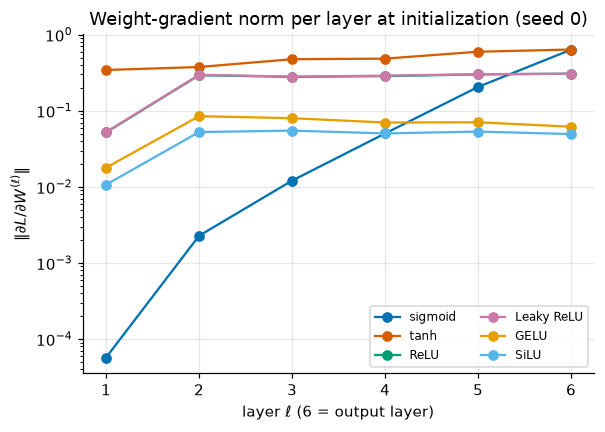

In [32]:
for (name, g), col in zip(grad_norms0.items(), COLORS):
    plt.semilogy(range(1, 7), g, "o-", color=col, label=name)
plt.xlabel("layer $\\ell$ (6 = output layer)")
plt.ylabel("$\\|\\partial L / \\partial W^{(\\ell)}\\|$")
plt.title("Weight-gradient norm per layer at initialization (seed 0)")
plt.legend(fontsize=8, ncol=2)
plt.show()

The sigmoid network stands apart: going backwards from the output, its weight-gradient norms shrink by a factor of 3 to 5 per layer, and by 40 into the first layer, so the first layer's gradient is about $10^4$ times smaller than the output layer's. The other activations keep layers 2–6 within a factor of about 2 of each other. For the ReLU family the first layer is about 5 times smaller than the rest (its input is the 2-D data rather than a 64-unit layer, so each unit's gradient row has only two entries), and GELU and SiLU have smaller gradients overall than ReLU, because the ReLU-derived Kaiming scale is only an approximation for them. None of this comes close to the sigmoid's factor of $10^4$. This is the chain argument of Section 2 in a real network: every sigmoid layer multiplies the backward signal by $\sigma'(A) \le \tfrac14$, and Xavier initialization with gain 1 does not compensate for that.

Now the training runs: 6 activations × 3 seeds.

In [33]:
def train_mlp(act_name, seed, steps=2000, lr=0.1):
    net = make_mlp(act_name, seed=seed)
    opt = torch.optim.SGD(net.parameters(), lr=lr)
    losses = []
    for _ in range(steps):
        opt.zero_grad()
        loss = F.cross_entropy(net(X_tr), y_tr)
        loss.backward()
        opt.step()
        losses.append(loss.item())
    with torch.no_grad():
        acc_tr = (net(X_tr).argmax(1) == y_tr).float().mean().item()
        acc_ho = (net(X_ho).argmax(1) == y_ho).float().mean().item()
    return net, torch.tensor(losses), acc_tr, acc_ho


results = {name: [train_mlp(name, seed) for seed in range(3)] for name in ACTIVATIONS}
print(f"{'activation':11s} {'final loss':>18s} {'train acc':>16s} {'held-out acc':>16s}   (mean ± std over 3 seeds;")
print(" " * 69 + "loss: average of the last 100 steps)")
summary = {}
for name, runs in results.items():
    fl = torch.tensor([r[1][-100:].mean().item() for r in runs])
    tr = torch.tensor([r[2] for r in runs])
    ho = torch.tensor([r[3] for r in runs])
    summary[name] = (fl.mean().item(), tr.mean().item(), ho.mean().item())
    print(f"{name:11s} {fl.mean():9.3f} ± {fl.std():.3f}   {tr.mean():8.3f} ± {tr.std():.3f}   {ho.mean():8.3f} ± {ho.std():.3f}")
print(f"\nln 3 = {math.log(3):.4f}")

activation          final loss        train acc     held-out acc   (mean ± std over 3 seeds;
                                                                     loss: average of the last 100 steps)
sigmoid         1.099 ± 0.000      0.346 ± 0.032      0.334 ± 0.042
tanh            0.115 ± 0.008      0.944 ± 0.024      0.921 ± 0.014
ReLU            0.109 ± 0.048      0.970 ± 0.007      0.943 ± 0.002
Leaky ReLU      0.113 ± 0.009      0.969 ± 0.009      0.937 ± 0.007
GELU            0.096 ± 0.005      0.964 ± 0.004      0.941 ± 0.004
SiLU            0.176 ± 0.063      0.963 ± 0.002      0.944 ± 0.001

ln 3 = 1.0986


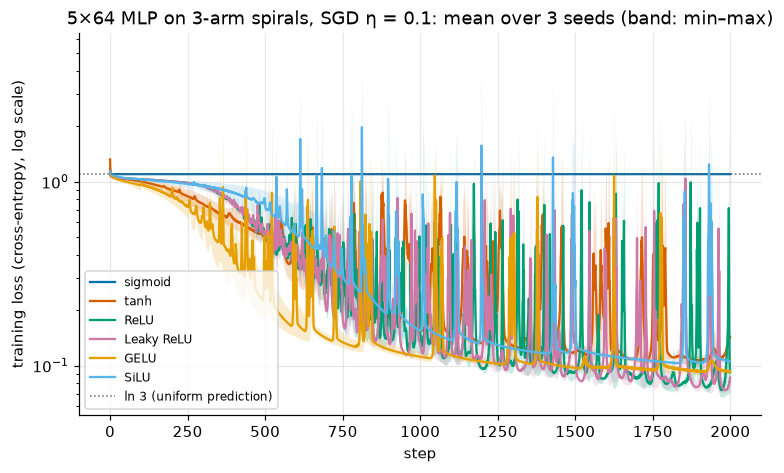

In [34]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for (name, runs), col in zip(results.items(), COLORS):
    curves = torch.stack([r[1] for r in runs])                 # (3, steps)
    ax.plot(curves.mean(0), color=col, label=name)
    ax.fill_between(range(curves.shape[1]), curves.min(0).values, curves.max(0).values, color=col, alpha=0.2, lw=0)
ax.axhline(math.log(3), color="0.4", ls=":", lw=1, label="ln 3 (uniform prediction)")
ax.set_yscale("log")
ax.set_xlabel("step")
ax.set_ylabel("training loss (cross-entropy, log scale)")
ax.set_title("5×64 MLP on 3-arm spirals, SGD η = 0.1: mean over 3 seeds (band: min–max)")
ax.legend(fontsize=8)
plt.show()

What we measured, for **this** setup (depth 5, width 64, full-batch SGD with $\eta = 0.1$, 2000 steps, 3 seeds):

- **Sigmoid did not learn at all**: the loss sits at $\ln 3$, the loss of predicting the uniform distribution, for all three seeds, and accuracy is near chance. The output layer does get gradient, but all it can learn without useful hidden features is the class frequencies, which are already uniform.
- **All five other activations learned the spirals**: mean training accuracy 0.94 (tanh) to 0.97 (ReLU), held-out accuracy 0.92 (tanh) to 0.94. GELU's loss fell fastest early on (below 0.2 by step 500 for its mean curve), and tanh ended slightly behind the ReLU family; the differences among ReLU, Leaky ReLU, GELU and SiLU are comparable to the seed-to-seed spread, so three seeds do not rank them (notebook 26 discusses how many runs a ranking needs).
- **The curves are spiky** for every activation except the sigmoid: single steps that jump the loss up before it recovers. A learning rate of 0.1 is near the edge of stability for these networks; learning rates and their schedules are notebook 19's subject. This is also why the table reports the loss averaged over the last 100 steps.

These are empirical findings for one small task, not general laws. In particular, the sigmoid failure is about **gradient scale**: an optimizer that rescales each parameter's step by the size of its recent gradients does not care that the first layer's gradients are 100 times smaller. Adam (notebook 19) is such an optimizer. Here is the sigmoid network again, trained with `torch.optim.Adam` (used as a black box for now):

In [35]:
for seed in range(3):
    net = make_mlp("sigmoid", seed=seed)
    opt = torch.optim.Adam(net.parameters(), lr=0.003)
    for _ in range(1000):
        opt.zero_grad()
        loss = F.cross_entropy(net(X_tr), y_tr)
        loss.backward()
        opt.step()
    with torch.no_grad():
        acc = (net(X_tr).argmax(1) == y_tr).float().mean().item()
    print(f"sigmoid + Adam, seed {seed}: final loss {loss.item():.3f}, training accuracy {acc:.3f}")

sigmoid + Adam, seed 0: final loss 0.058, training accuracy 0.977


sigmoid + Adam, seed 1: final loss 0.117, training accuracy 0.936


sigmoid + Adam, seed 2: final loss 0.064, training accuracy 0.981


With Adam the same sigmoid networks learn the spirals. So "sigmoid networks cannot be trained" is too strong; "with plain SGD, gradients through stacked sigmoid layers are too small to make progress" is what we observed. The ReLU family removes the problem at the source rather than relying on the optimizer, and in much deeper networks (dozens of layers) the shrinkage compounds beyond what step rescaling repairs — which, together with ReLU's low cost, is why it displaced the sigmoid in hidden layers. (The sigmoid remains the right **output** function for binary probabilities, notebook 09, and appears as a **gate** inside LSTMs and SiLU.)

The decision boundaries of the seed-0 networks:

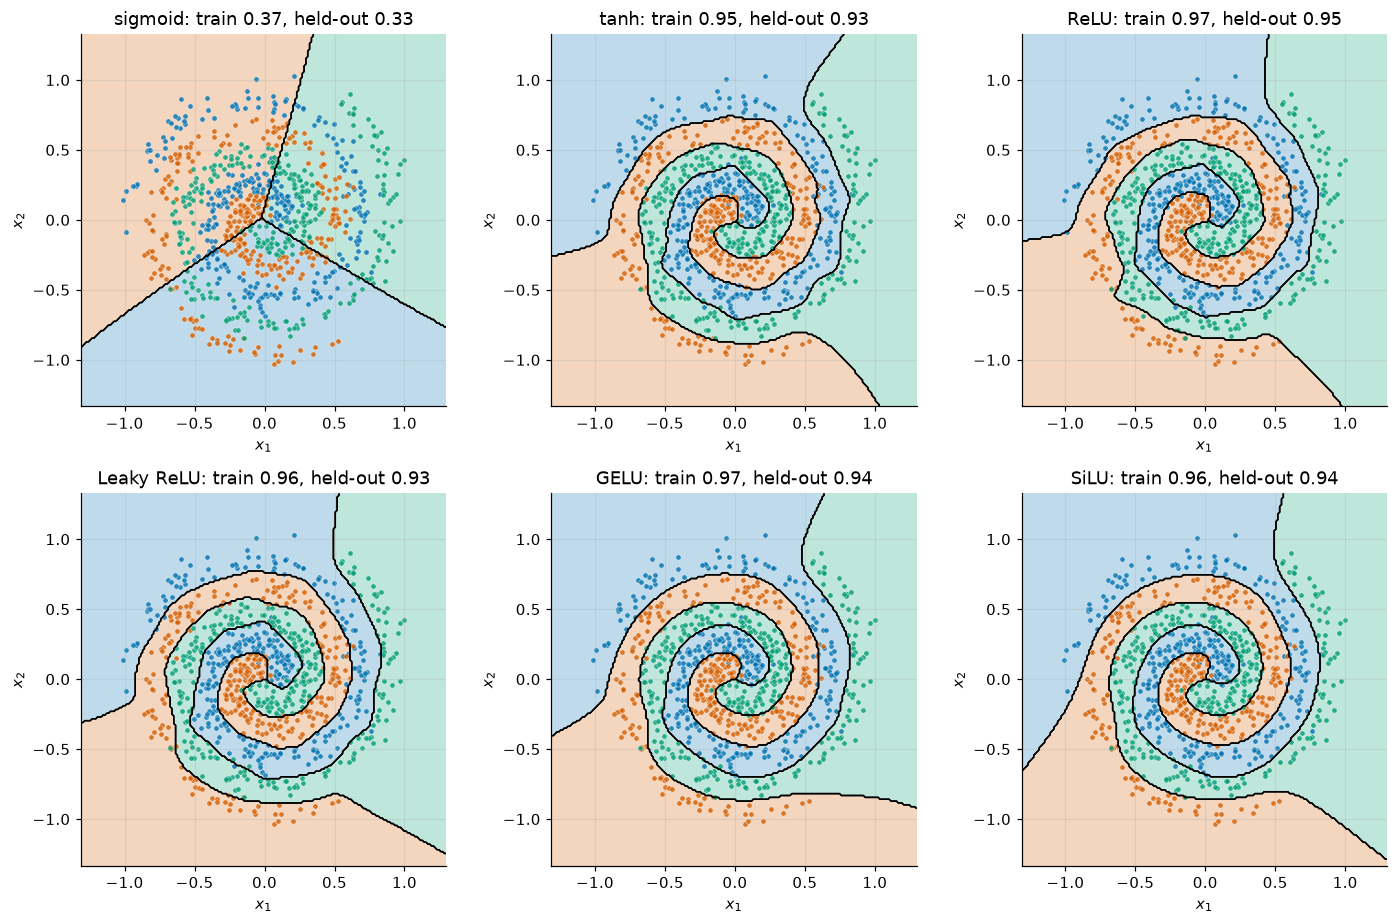

In [36]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for ax, (name, runs) in zip(axes.flat, results.items()):
    net, _, acc_tr, acc_ho = runs[0]
    plot_decision_boundary(lambda G, net=net: net(G).argmax(1), X_tr, y_tr, ax=ax,
                           title=f"{name}: train {acc_tr:.2f}, held-out {acc_ho:.2f}")
    ax.legend().remove()
plt.tight_layout()
plt.show()

The sigmoid network's regions are three nearly straight wedges meeting at the center, which ignore the spiral structure. The other five all follow the arms, with boundaries that look alike at this resolution; they differ outside the data (for example in the corners), where nothing constrains them. Section 6 looks more closely at how ReLU and GELU networks differ.

### Checkpoint 5.1

From `grad_norms0`, compute `ratio_sig` and `ratio_relu`: for the sigmoid and the ReLU network, the first layer's weight-gradient norm divided by the output layer's (Python floats). Then compute `per_layer_sig`, the **geometric mean** shrink factor per layer for the sigmoid network, $(\text{ratio\_sig})^{1/5}$ (five steps from layer 6 back to layer 1). Compare it with $\tfrac14$.

<details>
<summary><b>💡 Hint</b></summary>

`grad_norms0["sigmoid"][0] / grad_norms0["sigmoid"][-1]`, and `ratio_sig ** (1 / 5)`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"first/last: sigmoid {ratio_sig:.2e}, ReLU {ratio_relu:.2e};  sigmoid per-layer factor {per_layer_sig:.3f}")

In [ ]:
check_close(ratio_sig, grad_norms0["sigmoid"][0] / grad_norms0["sigmoid"][-1], "ratio_sig")
check_close(ratio_relu, grad_norms0["ReLU"][0] / grad_norms0["ReLU"][-1], "ratio_relu")
check_close(per_layer_sig, ratio_sig ** 0.2, "per_layer_sig")
passed("Checkpoint 5.1")

## 6. A representational view: ReLU networks are piecewise linear

Notebook 12 showed that a one-hidden-layer ReLU network of one input is piecewise linear. The same holds for any depth and any number of inputs: for a fixed **activation pattern** (which units are on), every ReLU acts as either the identity or zero, so the network is an affine function of its input. The input space is therefore cut into **linear regions**, one per activation pattern that actually occurs, and the network is affine on each. A GELU or SiLU network has no such regions: it is smooth, and curved everywhere.

We can count regions along a 1-D line through input space, $\mathbf x(t) = \mathbf p + t\,\mathbf d$: sample many $t$, record the activation pattern of every hidden unit at each point (with hooks, again), and count how often the pattern changes. A fine grid can miss tiny regions, so the count is a lower bound. We compare the seed-0 ReLU network of Section 5 before and after training, along a line that cuts through the spirals.

In [39]:
def activation_patterns(net, X):
    """(P, total hidden units) bool tensor: the sign pattern of every hidden pre-activation, via forward hooks."""
    pats = []
    hooks = [m.register_forward_hook(lambda m, inp, out: pats.append(inp[0] > 0))
             for m in net if not isinstance(m, nn.Linear)]
    with torch.no_grad():
        net(X)
    for h in hooks:
        h.remove()
    return torch.cat(pats, dim=1)


def count_regions_on_line(net, p, d, t):
    pts = p + t[:, None] * d                     # (P, 2)
    pats = activation_patterns(net, pts)
    changes = (pats[1:] != pats[:-1]).any(1)     # (P - 1,)
    return int(changes.sum().item()) + 1


# To avoid rounding artifacts we work in float64, on copies of the networks.
p_line = torch.tensor([-1.2, -0.2], dtype=f64)                # the line runs from (-1.2, -0.2) to (1.2, 0.6)
d_line = torch.tensor([2.4, 0.8], dtype=f64)
relu_init = make_mlp("ReLU", seed=0).double()
relu_trained = copy.deepcopy(results["ReLU"][0][0]).double()
gelu_trained = copy.deepcopy(results["GELU"][0][0]).double()
for n_grid in [50_001, 200_001]:
    t_grid = torch.linspace(0, 1, n_grid, dtype=f64)
    for label, net in [("ReLU, at initialization", relu_init), ("ReLU, trained", relu_trained)]:
        print(f"{n_grid:7d} grid points, {label:24s}: {count_regions_on_line(net, p_line, d_line, t_grid)} linear pieces")

  50001 grid points, ReLU, at initialization : 281 linear pieces
  50001 grid points, ReLU, trained           : 526 linear pieces


 200001 grid points, ReLU, at initialization : 281 linear pieces
 200001 grid points, ReLU, trained           : 528 linear pieces


Now the shape of the output itself. On each linear piece the second derivative along the line is 0, so the second difference $ig(f(t + \Delta t) - 2f(t) + f(t - \Delta t)ig)/\Delta t^2$ is 0 up to rounding except where a kink falls between the three samples. For a GELU network it should be nonzero everywhere.

ReLU: fraction of grid points with |second difference|/Δt² > 1e-3: 0.021


GELU: fraction of grid points with |second difference|/Δt² > 1e-3: 1.000


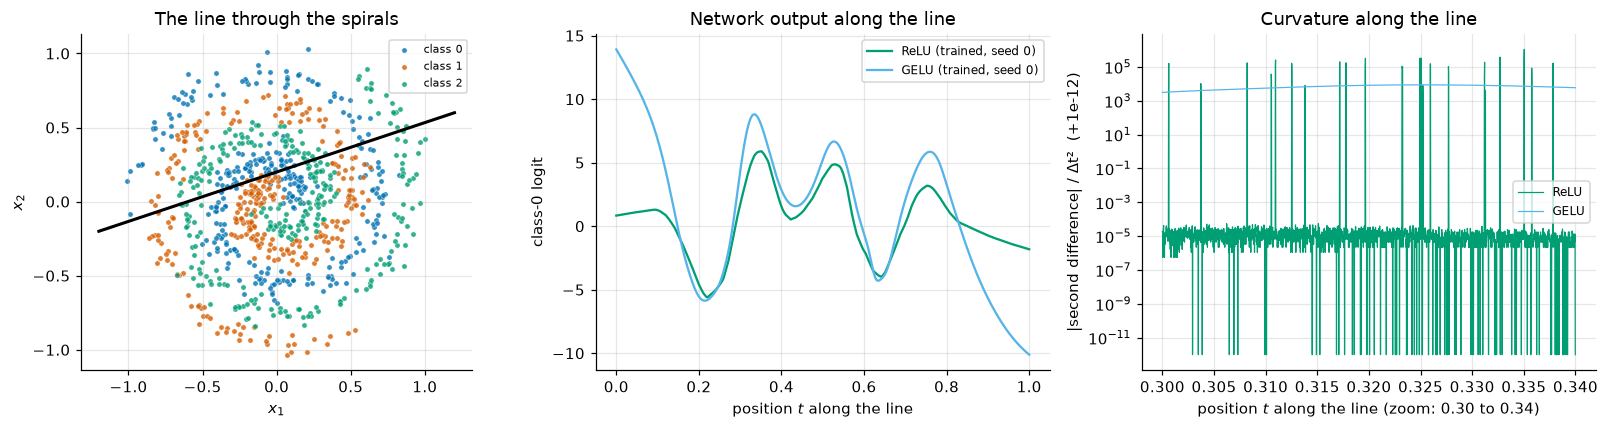

In [40]:
t_line = torch.linspace(0, 1, 50_001, dtype=f64)
pts = p_line + t_line[:, None] * d_line                       # (50001, 2)
dt = (t_line[1] - t_line[0]).item()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_dataset(X_tr, y_tr, ax=axes[0], title="The line through the spirals")
axes[0].plot(pts[:, 0], pts[:, 1], color="black", lw=2)
axes[0].legend(fontsize=7)
zoom = (t_line > 0.30) & (t_line < 0.34)
for name, net, col in [("ReLU", relu_trained, COLORS[2]), ("GELU", gelu_trained, COLORS[5])]:
    with torch.no_grad():
        f_line = net(pts)[:, 0]                               # class-0 logit along the line, (50001,)
    curvature = (f_line[2:] - 2 * f_line[1:-1] + f_line[:-2]).abs() / dt**2     # (49999,)
    print(f"{name}: fraction of grid points with |second difference|/Δt² > 1e-3: {(curvature > 1e-3).double().mean().item():.3f}")
    axes[1].plot(t_line, f_line, color=col, label=f"{name} (trained, seed 0)")
    axes[2].semilogy(t_line[1:-1][zoom[1:-1]], curvature[zoom[1:-1]] + 1e-12, color=col, lw=0.8, label=name)
axes[1].set_xlabel("position $t$ along the line")
axes[1].set_ylabel("class-0 logit")
axes[1].set_title("Network output along the line")
axes[1].legend(fontsize=8)
axes[2].set_xlabel("position $t$ along the line (zoom: 0.30 to 0.34)")
axes[2].set_ylabel("|second difference| / Δt²  (+1e-12)")
axes[2].set_title("Curvature along the line")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Counting.** At initialization the ReLU network already has 281 linear pieces along this line; after training it has 526 (528 on a 4× finer grid, so the coarse grid missed only a couple of tiny pieces). Training nearly doubled the number of bends along the line, which runs through the data where the network has to follow the spiral arms.

**Curvature.** In the zoomed panel, the ReLU network's second difference sits at about $10^{-5}$, which is float64 rounding divided by $\Delta t^2 = 4 \times 10^{-10}$, except for isolated spikes of $10^5$ to $10^6$ at the kinks: only 2.1% of grid points exceed $10^{-3}$. The GELU network's curvature is about $10^3$–$10^4$ and smooth at **every** point (100% exceed $10^{-3}$). The two output curves in the middle panel look similar at a glance; a ReLU network imitates a curve with many short straight segments.

Both kinds of function fit the spirals (Section 5). Which is better is task-dependent; one argument made for smooth activations is that their gradients change continuously with the input, but the case for GELU in Transformers rests mainly on empirical results (Hendrycks and Gimpel, 2016, and the model papers that adopted it).

## Exercises

### Exercise 1 (modify): Leaky ReLU against dead units

The cell below reruns Section 3's bias $-1.5$ experiment. Run it as given (ReLU), then change `ACT` to `lambda: nn.LeakyReLU(0.01)` and to `lambda: nn.LeakyReLU(0.1)`. The monitor still reports, per layer, the fraction of units whose pre-activation is **negative on every training input** (for Leaky ReLU these units are not dead in the gradient sense, they are only "off").

1. How does the first-layer "off" fraction evolve for each activation? Why can it change at all with Leaky ReLU, when it could not with ReLU?
2. Compare the final accuracies with the bias-0 ReLU baseline of Section 3. Why does $\alpha = 0.01$ help less than $\alpha = 0.1$?

<details>
<summary><b>💡 Hint</b></summary>

For a unit with $A_{ij} < 0$ for all $i$, the Leaky ReLU gives $\partial L/\partial A_{ij} = \alpha\,G_{ij}$, not 0. So its weights and bias receive a gradient $\alpha$ times what a live unit with the same upstream gradient would get. Does the bias have a reason to move upwards?

</details>

In [41]:
ACT = nn.ReLU

net_ex1 = relu_mlp(act=ACT, first_bias=-1.5)
hist_ex1 = train_monitored(net_ex1, X_sp, y_sp, lr=0.5, steps=1500, every=250)
for t, loss, acc, dead in hist_ex1:
    print(f"step {t:5d}: loss {loss:.3f}, accuracy {acc:.3f}, 'off' fraction per layer {[round(d, 2) for d in dead]}")
net_ex1.zero_grad()
F.cross_entropy(net_ex1(X_sp), y_sp).backward()
with torch.no_grad():
    off1 = ~((X_sp @ net_ex1[0].weight.T + net_ex1[0].bias) > 0).any(0)
print(f"layer-1 units off everywhere: {off1.sum().item()}; max |bias gradient| among them: "
      f"{net_ex1[0].bias.grad[off1].abs().max().item() if off1.any() else float('nan'):.2e}")

step     0: loss 1.100, accuracy 0.333, 'off' fraction per layer [0.83, 0.0, 0.02]
step   250: loss 0.925, accuracy 0.502, 'off' fraction per layer [0.83, 0.02, 0.06]
step   500: loss 0.802, accuracy 0.556, 'off' fraction per layer [0.83, 0.02, 0.03]
step   750: loss 0.669, accuracy 0.678, 'off' fraction per layer [0.83, 0.02, 0.06]
step  1000: loss 0.612, accuracy 0.696, 'off' fraction per layer [0.83, 0.03, 0.05]
step  1250: loss 0.652, accuracy 0.693, 'off' fraction per layer [0.83, 0.02, 0.02]
step  1500: loss 0.613, accuracy 0.748, 'off' fraction per layer [0.83, 0.02, 0.02]
layer-1 units off everywhere: 53; max |bias gradient| among them: 0.00e+00


*Your answer:*

### Exercise 2 (implement): Leaky ReLU as a custom autograd Function

Notebook 05 wrote custom `torch.autograd.Function`s. Implement `LeakyReLUFn` with a forward that computes $\max(\alpha z, z)$ elementwise (use `torch.where`) and a backward that returns the VJP $G \odot \varphi'(z)$, with $\varphi'(z) = 1$ for $z > 0$ and $\alpha$ for $z \le 0$ (PyTorch's convention at 0). `alpha` is a Python float passed as the second argument to `apply`; it needs no gradient, so `backward` returns `None` for it.

The check compares values and gradients with `F.leaky_relu` (including at exactly 0) and runs `gradcheck`.

<details>
<summary><b>💡 Hint</b></summary>

In `forward(ctx, z, alpha)`: `ctx.save_for_backward(z)`, `ctx.alpha = alpha`, return `torch.where(z > 0, z, alpha * z)`. In `backward(ctx, grad_out)`: `(z,) = ctx.saved_tensors`, return `grad_out * torch.where(z > 0, 1.0, ctx.alpha)` (match dtypes, e.g. via `torch.ones_like(z)`), and `None`. `gradcheck` needs `float64` inputs away from 0, where the function is not differentiable.

</details>

In [ ]:
class LeakyReLUFn(torch.autograd.Function):
    @staticmethod
    def forward(ctx, z, alpha):
        # YOUR CODE HERE
        raise NotImplementedError

    @staticmethod
    def backward(ctx, grad_out):
        # YOUR CODE HERE
        raise NotImplementedError

In [ ]:
_z = torch.tensor([-1e300, -2.0, -0.5, -0.0, 0.0, 0.5, 3.0, 1e300], dtype=f64, requires_grad=True)   # incl. ±0 and extremes
_out = LeakyReLUFn.apply(_z, 0.1)
check_close(_out, F.leaky_relu(_z, 0.1), "forward values", rtol=0, atol=1e-15)
_G = torch.tensor([2.0, 1.0, -2.0, 4.0, 3.0, 0.5, -1.0, 2.0], dtype=f64)
(_g_mine,) = torch.autograd.grad(_out, _z, grad_outputs=_G)
(_g_ref,) = torch.autograd.grad(F.leaky_relu(_z, 0.1), _z, grad_outputs=_G)
check_close(_g_mine, _g_ref, "gradient (including at z = 0)", rtol=0, atol=1e-15)
set_seed(1)
_zz = torch.randn(6, 7, dtype=f64)
_zz = (_zz + 0.1 * _zz.sign()).requires_grad_(True)           # keep entries away from the kink
check(torch.autograd.gradcheck(lambda t: LeakyReLUFn.apply(t, 0.2), (_zz,)), "gradcheck failed")
_f32 = LeakyReLUFn.apply(torch.randn(2, 3), 0.01)
check_shape(_f32, (2, 3), "output for a (2, 3) float32 input")
check(_f32.dtype == torch.float32, "the output should keep the input's dtype")
passed("Exercise 2")

### Exercise 3 (debug): a ReLU too many

`train_checkerboard(seed)` trains a 3-hidden-layer ReLU MLP on the checkerboard (two classes) and returns the trained network, which is supposed to output **logits** for `F.cross_entropy`. The buggy version (in the comments) runs without errors and, for some seeds, trains perfectly well. For others it stalls at a high loss. Find the bug, fix it, and then explain in the markdown cell below **why** it fails only for some seeds.

<details>
<summary><b>💡 Hint</b></summary>

Look at the last module. What range of values can the logits take? For an example where both logits come out as exactly 0, what are the predicted probabilities, and what gradient reaches the last `nn.Linear`? The demonstration cell after the check prints the fraction of training examples with all-zero logits.

</details>

In [44]:
X_cb, y_cb = make_checkerboard(n=800, seed=0)        # (800, 2), (800,)


def check_trains_all_seeds(train_fn, seeds=(0, 1, 2), threshold=0.85):
    """The check used below: train with each seed and require training accuracy > threshold for every seed."""
    accs = []
    for seed in seeds:
        net = train_fn(seed)
        with torch.no_grad():
            accs.append((net(X_cb).argmax(1) == y_cb).float().mean().item())
    check(min(accs) > threshold,
          f"training accuracies for seeds {list(seeds)}: {[round(a, 3) for a in accs]}; every seed should exceed {threshold}")
    return accs

In [ ]:
def train_checkerboard(seed, steps=1500, lr=0.5):
    set_seed(seed)
    # Buggy version:
    #     net = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(),
    #                         nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2), nn.ReLU())
    # YOUR CODE HERE
    raise NotImplementedError
    opt = torch.optim.SGD(net.parameters(), lr=lr)
    for _ in range(steps):
        opt.zero_grad()
        F.cross_entropy(net(X_cb), y_cb).backward()
        opt.step()
    return net

In [ ]:
_accs = check_trains_all_seeds(train_checkerboard)
print("training accuracies:", [round(a, 3) for a in _accs])
passed("Exercise 3")

Here is the original buggy function, run through **the same check**, which it fails. Then, for each seed, the fraction of training examples whose logits are all exactly 0. Since there are two classes, each such example has probabilities $(\tfrac12, \tfrac12)$ and loss exactly $\ln 2$, so "fraction × ln 2" is the part of the mean loss they account for. As a negative control, the same count for the corrected architecture (which has no ReLU on the logits) is 0 for every seed: exact zeros there would need both logits to land on 0.0 by coincidence.

In [47]:
def train_checkerboard_buggy(seed, steps=1500, lr=0.5, fixed=False):
    set_seed(seed)
    layers = [nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2)]
    net = nn.Sequential(*layers) if fixed else nn.Sequential(*layers, nn.ReLU())
    opt = torch.optim.SGD(net.parameters(), lr=lr)
    for _ in range(steps):
        opt.zero_grad()
        F.cross_entropy(net(X_cb), y_cb).backward()
        opt.step()
    return net


try:
    check_trains_all_seeds(train_checkerboard_buggy)
    print("the buggy version passed the check (unexpected)")
except AssertionError as e:
    print("buggy version fails the check:", e)

print()
for fixed in [False, True]:
    for seed in range(3):
        net = train_checkerboard_buggy(seed, fixed=fixed)
        with torch.no_grad():
            Z = net(X_cb)                                             # (800, 2)
            loss = F.cross_entropy(Z, y_cb).item()
            acc = (Z.argmax(1) == y_cb).float().mean().item()
            stuck = (Z == 0).all(1).float().mean().item()
        print(f"{'fixed' if fixed else 'buggy'}, seed {seed}: loss {loss:.3f}, accuracy {acc:.3f}, all-zero logits on "
              f"{stuck:.1%} of examples (their share of the loss: {stuck * math.log(2):.3f})")

buggy version fails the check: training accuracies for seeds [0, 1, 2]: [0.955, 0.634, 0.517]; every seed should exceed 0.85



buggy, seed 0: loss 0.110, accuracy 0.955, all-zero logits on 0.0% of examples (their share of the loss: 0.000)


buggy, seed 1: loss 0.605, accuracy 0.634, all-zero logits on 82.9% of examples (their share of the loss: 0.574)


buggy, seed 2: loss 0.510, accuracy 0.517, all-zero logits on 66.6% of examples (their share of the loss: 0.462)


fixed, seed 0: loss 0.126, accuracy 0.952, all-zero logits on 0.0% of examples (their share of the loss: 0.000)


fixed, seed 1: loss 0.094, accuracy 0.964, all-zero logits on 0.0% of examples (their share of the loss: 0.000)


fixed, seed 2: loss 0.223, accuracy 0.914, all-zero logits on 0.0% of examples (their share of the loss: 0.000)


### Exercise 4 (investigate): dead units and the learning rate

Section 3 created dead units with a bad bias. A large learning rate is a more common cause: one big step can push a unit's weights and bias so that its pre-activation is negative everywhere. How does the fraction of dead units after training depend on $\eta$?

Write the experiment loop: for every learning rate in `lrs` and every seed in `seeds`, train Section 3's network (`relu_mlp(seed=seed)`: 3 × 64 ReLU, bias 0) on the spirals with full-batch SGD for 400 steps, and record the dead fraction per hidden layer and the training accuracy **at the last step** in `dead_final[i, j]` (3 values) and `acc_final[i, j]`. The printing and plotting code is given. Before running, predict: will the dead fraction grow smoothly with $\eta$, or switch on above some value? Then answer:

1. Below which learning rate are essentially no units dead at the end? Above which are many?
2. Which layers are most affected, and is the effect consistent across seeds?
3. Does a high dead fraction come with low accuracy? What would you check first if a ReLU network stopped improving after a few high-learning-rate steps?

<details>
<summary><b>💡 Hint</b></summary>

`train_monitored(net, X_sp, y_sp, lr=lr, steps=400, every=400)` from Section 3 does the training and returns a history; its last entry is `(step, loss, accuracy, dead_fractions)`. Store `torch.tensor(dead_fractions)` in `dead_final[i, j]`. When interpreting, remember that first-layer dead units are permanent while deeper ones can revive, and that the snapshot is taken at the last step only.

</details>

In [ ]:
lrs = [0.1, 0.3, 1.0, 2.0, 3.0, 5.0]
seeds = [0, 1, 2]
dead_final = torch.zeros(len(lrs), len(seeds), 3)       # (learning rates, seeds, layers)
acc_final = torch.zeros(len(lrs), len(seeds))
# YOUR CODE HERE
raise NotImplementedError
for i, lr in enumerate(lrs):
    print(f"η = {lr:4.1f}: dead per layer (mean over seeds) {[round(v, 2) for v in dead_final[i].mean(0).tolist()]}, "
          f"accuracy per seed {[round(a, 3) for a in acc_final[i].tolist()]}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for l in range(3):
    m = dead_final[:, :, l].mean(1)
    axes[0].plot(lrs, m, "o-", color=COLORS[l], label=f"layer {l + 1} (mean)")
    for j in range(len(seeds)):
        axes[0].plot(lrs, dead_final[:, j, l], ".", color=COLORS[l], alpha=0.5)
axes[0].set_xscale("log")
axes[0].set_xlabel("learning rate η")
axes[0].set_ylabel("fraction of dead units after 400 steps")
axes[0].set_title("Dead ReLUs vs learning rate (dots: individual seeds)")
axes[0].legend(fontsize=8)
axes[1].plot(lrs, acc_final.nanmean(1), "o-", color=COLORS[7], label="mean")
for j in range(len(seeds)):
    axes[1].plot(lrs, acc_final[:, j], ".", color=COLORS[7], alpha=0.5)
axes[1].set_xscale("log")
axes[1].set_xlabel("learning rate η")
axes[1].set_ylabel("training accuracy after 400 steps")
axes[1].set_title("Accuracy vs learning rate")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

*Your conclusion:*

## Summary and what's next

- Backpropagation multiplies the upstream gradient **elementwise** by the activation's derivative: $\partial L/\partial A = G \odot \varphi'(A)$. What an activation does to training is mostly what values $\varphi'$ takes.
- **Sigmoid and tanh** are the same curve rescaled ($\tanh z = 2\sigma(2z) - 1$), but $\sigma' \le \tfrac14$ while $\tanh' \le 1$. Both **saturate**: the derivative decays exponentially for large $|z|$. Through a chain of $L$ sigmoids the gradient shrinks by a factor of at most $\tfrac14$ per layer (about $0.22$ per unit in our chain). Always-positive sigmoid outputs also force each per-example weight-gradient row of the next layer to share one sign (verified: 100% of rows).
- **ReLU** passes gradient unchanged through active units and is cheap and sparse (about half the units off at initialization). A unit that is off on **every** training input gets exactly zero gradient: in the first layer it is dead forever (53 of 64 units after a bias of $-1.5$, unchanged over 1500 steps), deeper ones can revive. Forward hooks measure this without touching the model.
- **Leaky ReLU, ELU, GELU, SiLU** keep slope 1 for large $z$ and change the negative side. GELU $= z\Phi(z)$ and SiLU $= z\sigma(z)$ are smooth and slightly non-monotone; the tanh approximation to GELU is within $5 \times 10^{-4}$. GELU is the Transformer default (Chapter 9).
- **Measured on 3-arm spirals** (5 × 64, SGD $\eta = 0.1$, 3 seeds): the sigmoid network did not learn at all (loss stuck at $\ln 3$; at initialization its first-layer gradient was about $10^4$ times smaller than the output layer's), while tanh, ReLU, Leaky ReLU, GELU and SiLU reached 94–97% training accuracy, with tanh slightly behind and the rest within the seed spread. Adam rescued the sigmoid network here, so the failure is one of gradient scale.
- **ReLU networks are piecewise linear**: along a line through the data, training increased the number of linear pieces from 281 to 526; a GELU network is curved everywhere.

Several results above depended on the **weight scale** at initialization: Xavier with a gain for sigmoid and tanh, Kaiming for ReLU, a bias that killed most of a layer, a tanh chain that stayed out of saturation only because its pre-activations stayed small. Notebook 17 first completes the picture at the output end with loss functions; then notebook 18 derives how the variance of activations and gradients propagates through depth, where the Xavier and Kaiming scales come from, and what happens in a 20- or 50-layer network when they are wrong.